# Robust image alignment with ALIKED LightGlue and MAGSAC++

This companion notebook takes two photographs, finds corresponding details,
estimates a homography, and checks whether the resulting alignment is usable.
It also identifies a known planar appearance from **one reference image**.

You should already know basic Python, NumPy arrays, and how to load images.
The examples cover planar surfaces and approximately planar scenes. A single
homography does not describe arbitrary 3D scenes with parallax or deformation.

We will:
1. Verify the tested OpenCV **5.1.0** runtime and the checksummed inputs.
2. Extract ALIKED features, match with LightGlue, and fit geometry with MAGSAC++.
3. Align real viewpoint, illumination, and document examples.
4. Locate a known object design from one reference and reject absent targets.
5. Measure independent geometric error, compare estimators, and test ECC refinement.
6. Inspect a parallax failure and run a small, explicitly synthetic noise study.

**Before running:** create the environment described in `README.md`, install
the pinned dependencies, build OpenCV with `scripts/build_opencv.sh`, and select
that environment's Jupyter kernel. Do not install another OpenCV wheel into the
same environment: it would replace the source-built `cv2` namespace. The
notebook checks the actual runtime rather than trusting a package filename.

In [1]:
import json
import platform
import subprocess
import sys
from io import BytesIO
from pathlib import Path

# Support launching Jupyter from this project or from the repository root.
candidates = [Path.cwd(), Path.cwd() / "Robust-Image-Alignment"]
PROJECT = next((path.resolve() for path in candidates
                if (path / "robust_image_alignment.py").is_file()), None)
if PROJECT is None:
    raise RuntimeError("Start Jupyter in Robust-Image-Alignment or its repository root.")
sys.path.insert(0, str(PROJECT))

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

# Use the released version for which the article records experimental evidence.
assert cv2.__version__ == "5.1.0", f"Expected OpenCV 5.1.0; found {cv2.__version__} at {cv2.__file__}"
cv2.setNumThreads(1)
torch.set_num_threads(4)
torch.manual_seed(0)
print({"OpenCV": cv2.__version__, "Python": platform.python_version(),
       "NumPy": np.__version__, "PyTorch": torch.__version__})
print("cv2 loaded from:", cv2.__file__)

{'OpenCV': '5.1.0', 'Python': '3.14.3', 'NumPy': '2.4.2', 'PyTorch': '2.10.0+cu126'}
cv2 loaded from: /tmp/robust-align-py314/lib/python3.14/site-packages/cv2/__init__.py


## Download and verify the inputs and weights

`download_assets.py` checks each file's SHA-256 digest and byte count against
`assets_manifest.json`. Existing verified downloads are reused. The Oxford
graffiti and Leuven sequences contain **real camera captures** and supplied
reference-to-moving homographies; the later noise study is synthetic.

For the form, the blank reference is a digital DMV template. The other
image is a phone photo of a printed, completed copy. The box and form are
qualitative examples without an independently measured homography. The manifest preserves
provenance and licensing notes; downloading an image does not relicense it.
Model weights are likewise pinned and verified before inference.

In [2]:
from download_assets import download_assets
from robust_image_alignment import (
    AlignmentConfig, FeatureMatcher, MatchResult, draw_matches,
    estimate_alignment, image_corners, load_image, project_points,
    refine_ecc, warp_alignment,
)
from run_experiments import geometric_error

ASSETS = download_assets(verbose=False)
manifest = json.loads((PROJECT / "assets_manifest.json").read_text())
print(f"Verified {len(manifest['files'])} input files.")
verification = subprocess.run(
    [sys.executable, str(PROJECT / "download_models.py")],
    check=True, capture_output=True, text=True,
)
print(verification.stdout.strip().splitlines()[-1])
pairs = {entry["id"]: entry for entry in manifest["pairs"]}

Verified 35 input files.


Verified both pretrained checkpoints in /home/spmallick/.cache/torch/hub/checkpoints


## Look at the actual inputs

The graffiti wall changes viewpoint; the Leuven building changes illumination.
The form has perspective distortion and added handwriting. The box photograph
contains a small known appearance within a cluttered scene. These are separate
capture problems, not just rotations of one image.

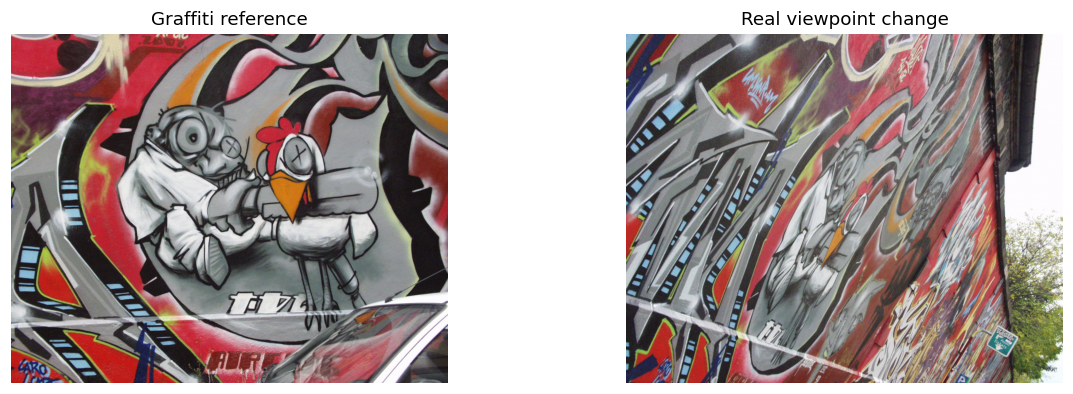

In [3]:
def show_images(items, columns=2, width=12):
    # Render BGR or grayscale inputs without depending on a GUI backend.
    rows = (len(items) + columns - 1) // columns
    figure, axes = plt.subplots(rows, columns, figsize=(width, 3.7 * rows), squeeze=False)
    for axis, (title, image) in zip(axes.flat, items):
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else image
        axis.imshow(rgb, cmap="gray" if image.ndim == 2 else None)
        axis.set_title(title)
        axis.axis("off")
    for axis in list(axes.flat)[len(items):]:
        axis.axis("off")
    figure.tight_layout()
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)

reference = load_image(ASSETS / pairs["graf_1_6"]["reference"])
moving = load_image(ASSETS / pairs["graf_1_6"]["moving"])
show_images([("Graffiti reference", reference), ("Real viewpoint change", moving)])

## ALIKED finds the features and LightGlue matches them

ALIKED's sparse deformable descriptor head learns where to sample supporting
features at 16 learned offsets around each keypoint in aliked-n16. LightGlue
then uses context within and between
images to establish correspondences. Their pretrained weights form a pair:
this notebook uses **`aliked-n16`** and **`LightGlue(features="aliked")`**.

The wrapper converts OpenCV BGR uint8 images to RGB tensors in `[0, 1]`, caps
the longest side at 1024 pixels without upsampling, and retains the extractor's
original-image coordinates. Do **not** scale those coordinates a second time.

In [4]:
matcher = FeatureMatcher("lightglue", device="auto", max_keypoints=2048, resize=1024)
print("Inference device:", matcher.device)
# Model loading is outside timing; references can be extracted once and cached.
reference_features = matcher.extract(reference)
moving_features = matcher.extract(moving)
print("Keypoints:", reference_features.keypoints.shape, moving_features.keypoints.shape)
print("Descriptors:", reference_features.descriptors.shape, moving_features.descriptors.shape)
print("Batched tensors:", {
    name: tuple(value.shape) for name, value in reference_features.tensors.items()
    if hasattr(value, "shape")
})

2026-11-20 11:25:34.385911282 [W:onnxruntime:Default, device_discovery.cc:211 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:91 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"
/home/spmallick/.venvs/cv-torch/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Inference device: cuda


Keypoints: (1514, 2) (1232, 2)
Descriptors: (1514, 128) (1232, 128)
Batched tensors: {'keypoints': (1, 1514, 2), 'descriptors': (1, 1514, 128), 'keypoint_scores': (1, 1514), 'image_size': (1, 2)}


## Follow the tensor indices back to image coordinates

Each row of LightGlue's `matches` contains one index into the reference
keypoints and one into the moving keypoints. The batched tensors keep one
image pair in batch dimension 0. This cell makes that indexing explicit;
`matcher.match(reference_features, moving_features)` provides the reusable
equivalent with timing and consistent empty-input handling.

LightGlue can stop before the ninth layer when enough point assignments
have stabilized. It can also prune confidently unmatchable points when
pruning is active for the device and point count.

237 tentative matches; coordinate shape (237, 2).


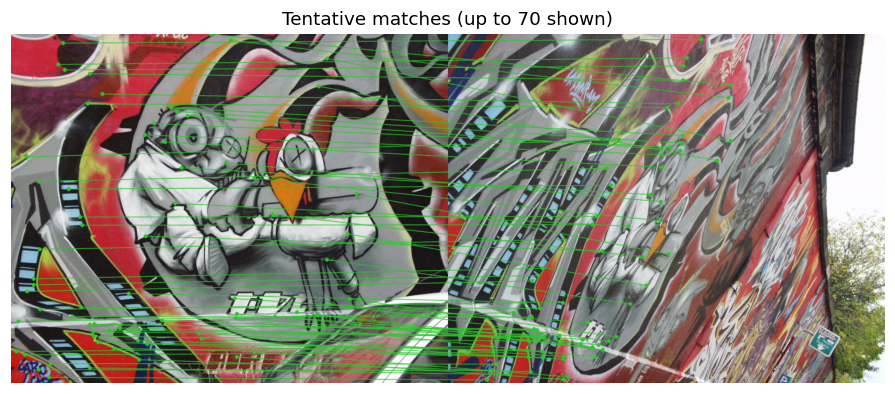

In [5]:
with torch.inference_mode():
    raw_matches = matcher.matcher({
        "image0": reference_features.tensors,
        "image1": moving_features.tensors,
    })
# Detach only the small correspondence output needed by OpenCV geometry.
indices = raw_matches["matches"][0].detach().cpu().numpy()
points_reference = reference_features.keypoints[indices[:, 0]]
points_moving = moving_features.keypoints[indices[:, 1]]
matches = matcher.match(reference_features, moving_features)
print(f"{len(points_reference)} tentative matches; coordinate shape {points_reference.shape}.")
show_images([("Tentative matches (up to 70 shown)", draw_matches(reference, moving, matches, max_draw=70))], columns=1)

## MAGSAC++ estimates the homography

Incorrect correspondences remain possible even with a learned matcher.
OpenCV's `USAC_MAGSAC` configuration uses MAGSAC++ to estimate robust geometry.
It accounts for uncertainty in the noise scale, while the OpenCV call still
takes an error threshold and iteration/confidence settings.

**Direction matters:** source points come first, so the call below estimates
**moving → reference**. The threshold is in original reference-image pixels.
A homography models a plane, or a camera rotation about its projection center;
it does not make parallax disappear.

In [6]:
H_direct, inlier_mask = cv2.findHomography(
    points_moving, points_reference,
    method=cv2.USAC_MAGSAC,
    ransacReprojThreshold=3.0,
    maxIters=10000,
    confidence=0.999,
)
if H_direct is None:
    raise RuntimeError("No homography could be estimated.")
print("Moving-to-reference homography:\n", H_direct / H_direct[2, 2])
print("Estimator-selected inliers:", int(inlier_mask.sum()))

# The production helper also checks spatial support and projected geometry.
config = AlignmentConfig()
result = estimate_alignment(matches, reference.shape, moving.shape, config, "magsac")
assert result.accepted, result.reasons
print({"accepted": result.accepted, "inliers": result.num_inliers,
       "reference_coverage": round(result.reference_coverage, 3)})

Moving-to-reference homography:
 [[ 1.37079331e+00  8.63813782e-01 -5.80881487e+02]
 [-6.38566556e-01  2.58769980e-01  3.03479096e+02]
 [-7.73521689e-04 -4.34993435e-04  1.00000000e+00]]
Estimator-selected inliers: 72
{'accepted': True, 'inliers': 72, 'reference_coverage': 0.528}


## Warp the image and preserve a valid-pixel mask

`warpPerspective` uses the moving-to-reference homography directly. Missing
pixels can appear black, but real image content can also be black; therefore
a warped source mask lets us keep genuine black pixels. The default mask
tests the nearest source pixel. Passing `full_support=True` instead uses
the same bilinear sampling as the image and drops border pixels that mix
real input with padding. We use that stricter mask for this overlay.

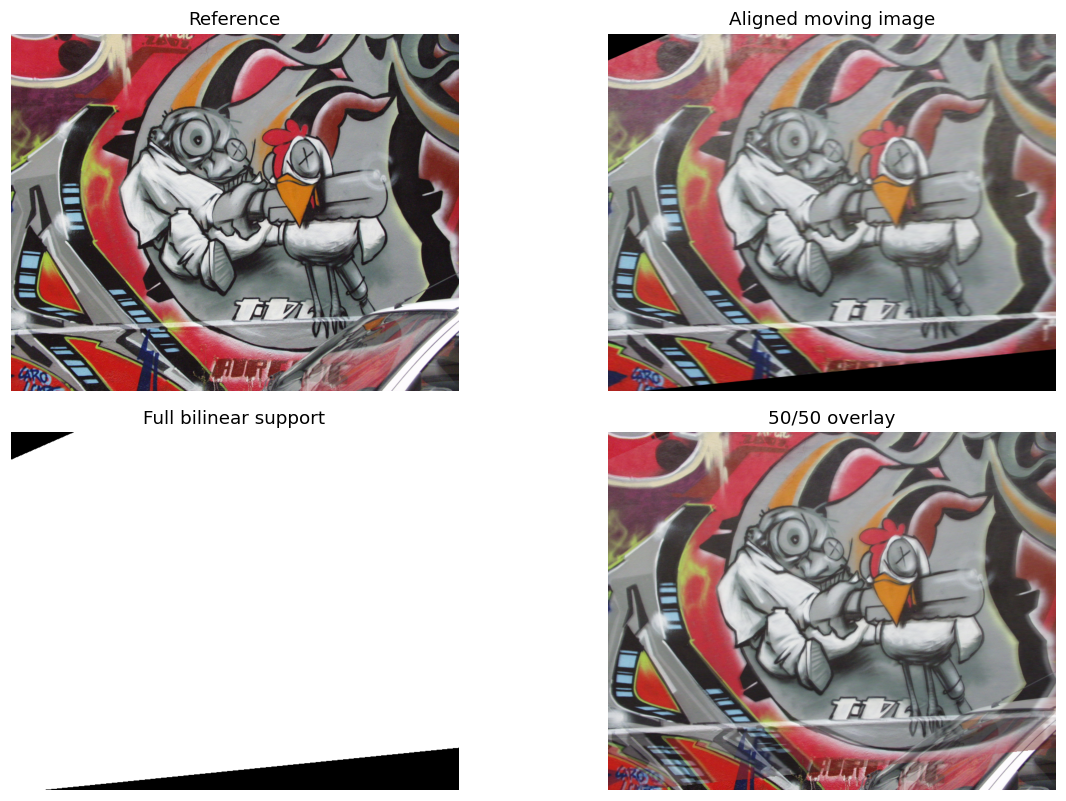

In [7]:
aligned, valid_mask = warp_alignment(moving, result, reference.shape, full_support=True)
overlay = cv2.addWeighted(reference, 0.5, aligned, 0.5, 0)
overlay[valid_mask == 0] = reference[valid_mask == 0]
show_images([
    ("Reference", reference), ("Aligned moving image", aligned),
    ("Full bilinear support", valid_mask), ("50/50 overlay", overlay),
])

## Measure on independent ground truth

Inlier reprojection error measures how well a model fits the matches it
selected. A wrong model can fit its own selected matches very well. Here we
instead construct a regular grid in the reference, map it with the dataset's
supplied homography, and evaluate estimated alignment only inside the true
overlap. The grid measures agreement with the supplied homography in
original reference-image pixels. The dataset authors estimated these
homographies and report a fit RMS below one pixel for each pair.

These are small teaching experiments on two capture sequences. The split
holds out image pairs, not entirely new scenes, so it is not a generalization
benchmark or a claim of state-of-the-art performance. CUDA and CPU can also
give different correspondences on the same pair. The default LightGlue
pipeline passed 8/8 on CUDA and 7/8 on both CPU and Apple MPS. On graf 1→6
all three passed the geometric checks. Only CUDA passed the 3 px criterion.

In [8]:
H_ground_truth = np.asarray(pairs["graf_1_6"]["homography_matrix"]).reshape(3, 3)
grid_error = geometric_error(result.H, H_ground_truth, reference.shape, moving.shape)
print({key: round(value, 3) if isinstance(value, float) else value
       for key, value in grid_error.items()})
print("Fit residual on selected inliers:", round(result.median_reprojection_error, 3), "px")
# Retain the actual images and estimate for the later refinement experiment.
demonstrations = {"graf_1_6": (reference, moving, matches, result, H_ground_truth)}

{'grid_median_error_px': 1.763, 'grid_p95_error_px': 2.226, 'grid_points': 661, 'corner_mean_error_px': 1.933}
Fit residual on selected inliers: 1.391 px


## Repeat on illumination change and a photographed document

The same pipeline handles different kinds of appearance change without
retraining on either target. The form's filled fields genuinely differ from
the blank template; an alignment overlay is not an instruction to erase or
ignore those differences. Neither form input supplies independent ground
truth, so its result is a qualitative demonstration.

leuven_1_6 {'accepted': True, 'inliers': 957, 'reasons': []}


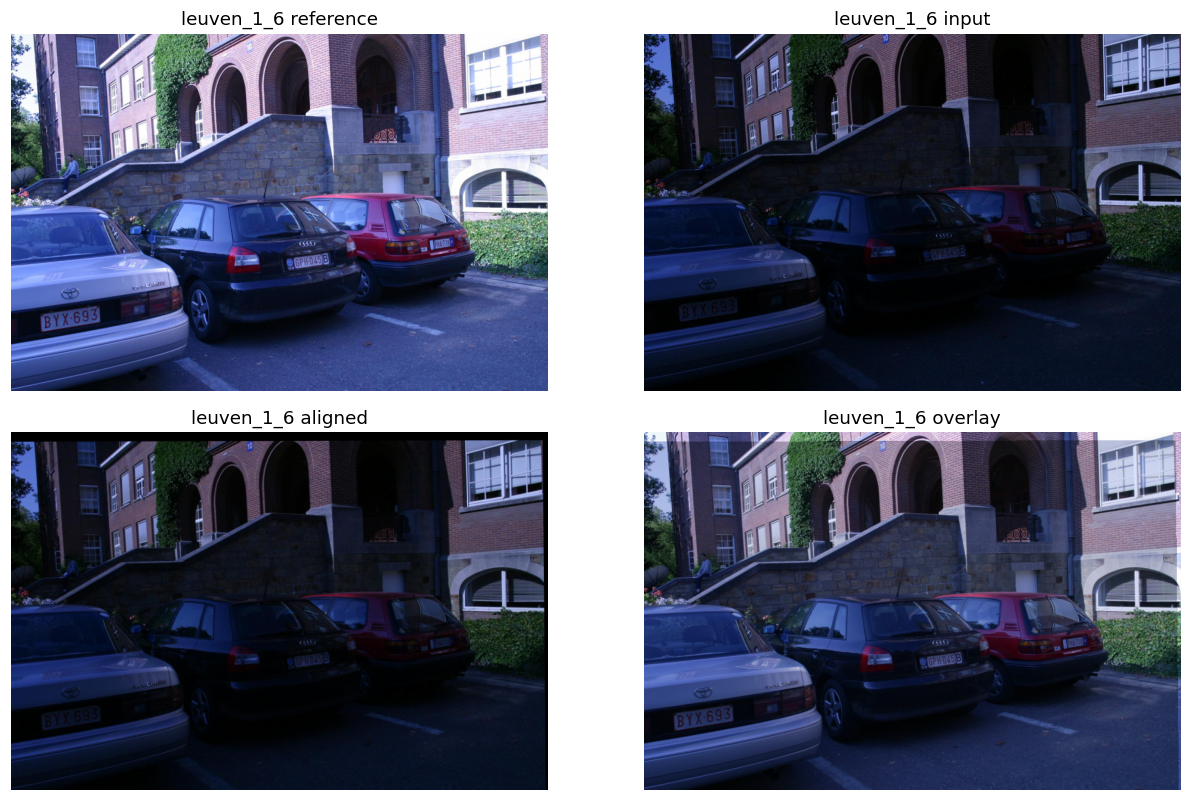

Independent grid error: {'grid_median_error_px': 0.15871146321296692, 'grid_p95_error_px': 0.4000726640224457, 'grid_points': 667, 'corner_mean_error_px': 0.41690462827682495}


document {'accepted': True, 'inliers': 1016, 'reasons': []}


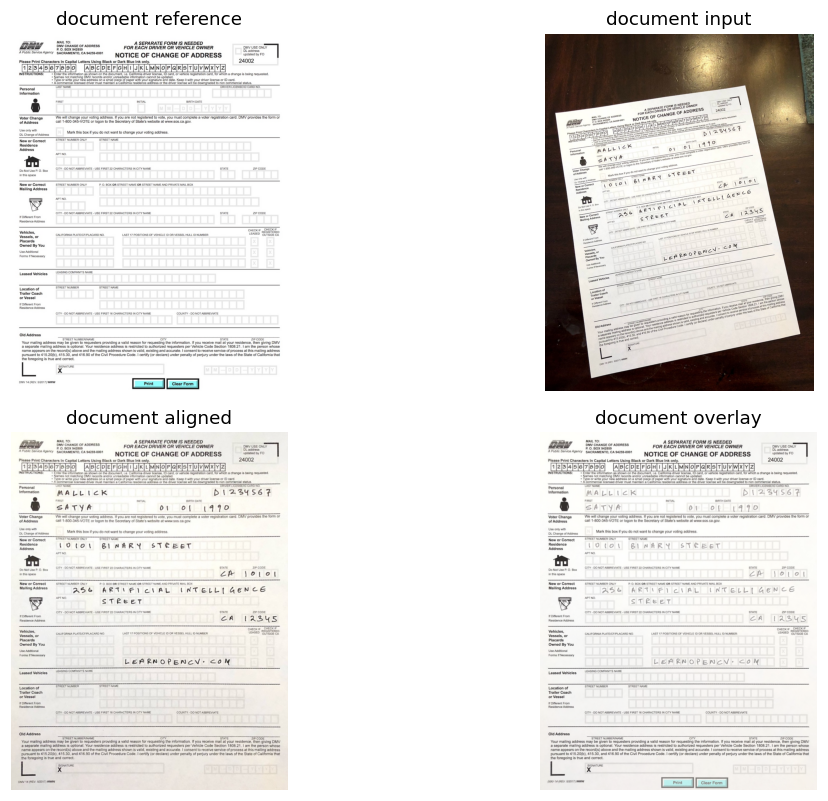

In [9]:
for name, reference_path, moving_path in [
    ("leuven_1_6", pairs["leuven_1_6"]["reference"], pairs["leuven_1_6"]["moving"]),
    ("document", "learnopencv/form.jpg", "learnopencv/scanned-form.jpg"),
]:
    ref, mov = load_image(ASSETS / reference_path), load_image(ASSETS / moving_path)
    found = matcher.match_images(ref, mov)
    fitted = estimate_alignment(found, ref.shape, mov.shape, config)
    print(name, {"accepted": fitted.accepted, "inliers": fitted.num_inliers, "reasons": fitted.reasons})
    assert fitted.accepted, (name, fitted.reasons)
    warped, support = warp_alignment(mov, fitted, ref.shape)
    mixed = cv2.addWeighted(ref, 0.5, warped, 0.5, 0)
    mixed[support == 0] = ref[support == 0]
    show_images([(name + " reference", ref), (name + " input", mov),
                 (name + " aligned", warped), (name + " overlay", mixed)])
    truth = np.asarray(pairs[name]["homography_matrix"]).reshape(3, 3) if name in pairs else None
    demonstrations[name] = (ref, mov, found, fitted, truth)
    if truth is not None:
        print("Independent grid error:", geometric_error(fitted.H, truth, ref.shape, mov.shape))

## Identify and locate a known appearance from one reference

We now enroll one image of the box design and look for it in a cluttered
photograph. Cache the reference features, match a query image, check geometry,
and project the reference boundary into the scene with the **inverse** H.

This identifies a known appearance, such as a particular cover or label. It
does not learn an entire semantic category from one example, distinguish
physical copies with identical printing, or recognize an unseen backside.
The acceptance gates below are transparent heuristics, not a calibrated
probability or a proven false-acceptance operating point.

{'identified': True, 'inliers': 134, 'reference_coverage': 0.661}


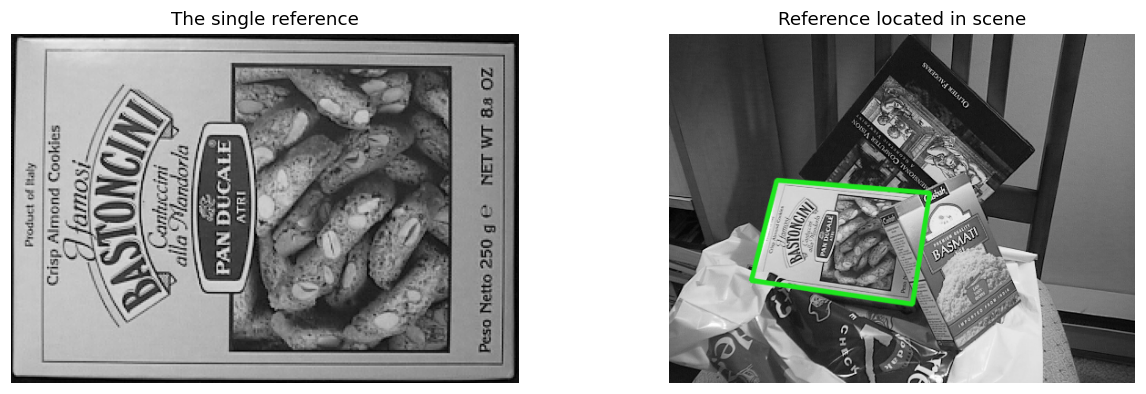

In [10]:
target = load_image(ASSETS / "opencv/box.png")
scene = load_image(ASSETS / "opencv/box_in_scene.png")
enrolled = matcher.extract(target)  # One reference image; no target-specific training.
query_features = matcher.extract(scene)
identification_matches = matcher.match(enrolled, query_features)
identification = estimate_alignment(identification_matches, target.shape, scene.shape, config)
assert identification.accepted, identification.reasons

localized = scene.copy()
# The helper has checked that the projected boundary is finite and plausible.
quad = np.rint(identification.projected_reference_quad).astype(np.int32)
cv2.polylines(localized, [quad], True, (30, 230, 30), 3, cv2.LINE_AA)
print({"identified": identification.accepted, "inliers": identification.num_inliers,
       "reference_coverage": round(identification.reference_coverage, 3)})
show_images([("The single reference", target), ("Reference located in scene", localized)])

## An absent target should produce a rejection

Repeat the same decision on two unrelated images. Passing these examples is
a useful regression check, not a measured false-positive rate. A production
catalogue needs many hard negatives, including similar designs and repeated
patterns. A small target should not be rejected merely for occupying little
of the scene: spatial coverage is checked in the reference coordinates.

In [11]:
for negative_path in ["opencv/fruits.jpg", "opencv/building.jpg"]:
    negative = load_image(ASSETS / negative_path)
    found = matcher.match(enrolled, matcher.extract(negative))
    decision = estimate_alignment(found, target.shape, negative.shape, config)
    print(Path(negative_path).name, {"accepted": decision.accepted,
          "matches": len(found.reference_points), "reasons": decision.reasons})
    assert not decision.accepted, "Unexpected acceptance: inspect this negative example."

fruits.jpg {'accepted': False, 'matches': 13, 'reasons': ['Only 4 inliers; need 12.', 'Invalid projected geometry: The projected reference crosses the projective horizon.']}
building.jpg {'accepted': False, 'matches': 13, 'reasons': ['Only 4 inliers; need 12.', 'Invalid projected geometry: The projected reference crosses the projective horizon.']}


## Extend to a small reference catalogue

Candidate verification scales naturally to a few enrolled references. For a
large catalogue, first retrieve a short candidate list, then run LightGlue
and geometric verification on that list. If several candidates pass, preserve
the ambiguity instead of silently calling the largest match count an identity.

In [12]:
catalogue = {
    "box design": (target, enrolled),
    "graffiti wall": (reference, reference_features),
    "blank form": (demonstrations["document"][0], matcher.extract(demonstrations["document"][0])),
}
candidates = []
for name, (reference_image, cached_features) in catalogue.items():
    found = matcher.match(cached_features, query_features)
    candidate = estimate_alignment(found, reference_image.shape, scene.shape, config)
    candidates.append((name, candidate.accepted, candidate.num_inliers))
print("Candidate decisions (name, accepted, inliers):", candidates)
accepted_names = [name for name, accepted, _ in candidates if accepted]
print("Identification:", accepted_names[0] if len(accepted_names) == 1 else "ambiguous or absent")

Candidate decisions (name, accepted, inliers): [('box design', True, 134), ('graffiti wall', False, 5), ('blank form', False, 5)]
Identification: box design


## Hold the matches fixed when comparing estimators

This comparison uses identical LightGlue correspondences and the same pixel
threshold for OpenCV's RANSAC and `USAC_MAGSAC` configurations. Their internal
robust-estimation machinery differs; this is a comparison of complete OpenCV
configurations, not an isolated replacement of one scoring formula.

Match count and fitted inlier residual are diagnostics. Independent geometric
error is the accuracy measure when dataset ground truth is available.

In [13]:
estimator_rows = []
for estimator in ["ransac", "magsac"]:
    fitted = estimate_alignment(matches, reference.shape, moving.shape, config, estimator)
    errors = geometric_error(fitted.H, H_ground_truth, reference.shape, moving.shape)
    estimator_rows.append({"estimator": estimator, "accepted": fitted.accepted,
                           "inliers": fitted.num_inliers,
                           "independent_median_px": errors["grid_median_error_px"],
                           "fit_median_px": fitted.median_reprojection_error})
for row in estimator_rows:
    print(row)

{'estimator': 'ransac', 'accepted': True, 'inliers': 69, 'independent_median_px': 2.3692450523376465, 'fit_median_px': 1.6420196294784546}
{'estimator': 'magsac', 'accepted': True, 'inliers': 72, 'independent_median_px': 1.762966275215149, 'fit_median_px': 1.391448736190796}


## Test ECC refinement rather than assuming it helps

ECC directly optimizes image agreement. It requires a reasonable initial
alignment and may improve, worsen, or fail on a pair. OpenCV ECC expects a
reference-to-moving initialization. The helper inverts the initial matrix
and normalizes it to a bottom-right entry of one, as required by OpenCV's
eight-parameter homography update. It masks the initial overlap in moving
coordinates and inverts the refined matrix to return moving → reference.

Compare before and after against independent geometry. A high correlation
value alone is not proof of a better alignment.

In [14]:
for name in ["graf_1_6", "leuven_1_6"]:
    ref, mov, found, fitted, truth = demonstrations[name]
    before = geometric_error(fitted.H, truth, ref.shape, mov.shape)["grid_median_error_px"]
    try:
        refined_H, correlation = refine_ecc(ref, mov, fitted.H)
        after = geometric_error(refined_H, truth, ref.shape, mov.shape)["grid_median_error_px"]
        print(name, {"before_px": round(before, 3), "after_px": round(after, 3),
                     "ECC_correlation": round(correlation, 4), "improved": after < before})
    except (cv2.error, ValueError, np.linalg.LinAlgError) as error:
        print(name, "ECC failed:", str(error).splitlines()[0])

graf_1_6 {'before_px': 1.763, 'after_px': 0.591, 'ECC_correlation': 0.8045, 'improved': True}


leuven_1_6 {'before_px': 0.159, 'after_px': 0.189, 'ECC_correlation': 0.9324, 'improved': False}


## A single homography cannot remove parallax

These stereo photographs contain surfaces at different depths. A homography
may align one dominant surface while leaving other surfaces doubled. Our
geometric acceptance gates can accept a well-supported plane; they do not
establish that every pixel in a 3D scene is aligned. Inspect the overlay and
use a different motion model or local/dense method when the task requires it.

{'accepted_plane': True, 'inliers': 887, 'reasons': []}


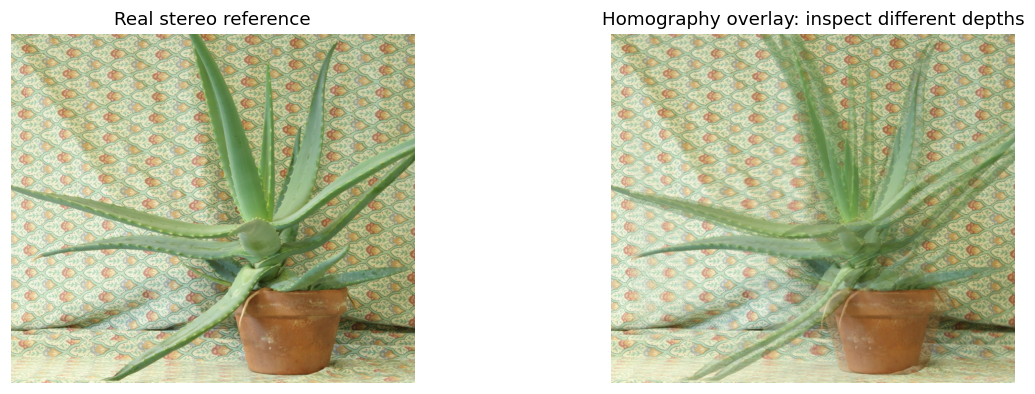

In [15]:
aloe_reference = load_image(ASSETS / "opencv/aloeL.jpg")
aloe_moving = load_image(ASSETS / "opencv/aloeR.jpg")
aloe_matches = matcher.match_images(aloe_reference, aloe_moving)
aloe_result = estimate_alignment(aloe_matches, aloe_reference.shape, aloe_moving.shape, config)
print({"accepted_plane": aloe_result.accepted, "inliers": aloe_result.num_inliers,
       "reasons": aloe_result.reasons})
if aloe_result.H is not None:
    # Explicitly permit diagnostic warping even if the acceptance gate rejected it.
    aloe_warped, aloe_valid = warp_alignment(aloe_moving, aloe_result, aloe_reference.shape,
                                             require_accepted=False)
    aloe_overlay = cv2.addWeighted(aloe_reference, 0.5, aloe_warped, 0.5, 0)
    aloe_overlay[aloe_valid == 0] = aloe_reference[aloe_valid == 0]
    show_images([("Real stereo reference", aloe_reference), ("Homography overlay: inspect different depths", aloe_overlay)])

## A controlled synthetic noise experiment

This study generates point correspondences from a known homography, adds
Gaussian coordinate noise, and replaces exactly 60% with uniform outliers.
Both OpenCV presets receive identical correspondences for each seed. The
sweep varies the reprojection threshold and the maximum median inlier
residual together. It compares the full configurations. Repeated patterns
in a photograph can produce much more coherent false correspondences.

The short notebook run uses three seeds. The saved article experiment records
its larger seed count separately; do not confuse either with real captures.

In [16]:
from run_experiments import run_estimator_study

synthetic_rows = run_estimator_study(seeds=3)
for noise in [0.5, 1.5, 3.0]:
    for estimator in ["ransac", "magsac"]:
        selected = [row for row in synthetic_rows
                    if row["noise_sigma_px"] == noise and row["threshold_px"] == 3.0
                    and row["estimator"] == estimator]
        errors = [row["grid_median_error_px"] for row in selected
                  if row["grid_median_error_px"] is not None]
        print({"synthetic_sigma_px": noise, "estimator": estimator,
               "accepted_runs": sum(row["accepted"] for row in selected),
               "runs": len(selected), "finite_fits": len(errors),
               "median_finite_model_error_px": round(float(np.median(errors)), 3) if errors else None})

{'synthetic_sigma_px': 0.5, 'estimator': 'ransac', 'accepted_runs': 3, 'runs': 3, 'finite_fits': 3, 'median_finite_model_error_px': 0.169}
{'synthetic_sigma_px': 0.5, 'estimator': 'magsac', 'accepted_runs': 3, 'runs': 3, 'finite_fits': 3, 'median_finite_model_error_px': 0.183}
{'synthetic_sigma_px': 1.5, 'estimator': 'ransac', 'accepted_runs': 3, 'runs': 3, 'finite_fits': 3, 'median_finite_model_error_px': 0.788}
{'synthetic_sigma_px': 1.5, 'estimator': 'magsac', 'accepted_runs': 3, 'runs': 3, 'finite_fits': 3, 'median_finite_model_error_px': 0.547}
{'synthetic_sigma_px': 3.0, 'estimator': 'ransac', 'accepted_runs': 0, 'runs': 3, 'finite_fits': 3, 'median_finite_model_error_px': 3.115}
{'synthetic_sigma_px': 3.0, 'estimator': 'magsac', 'accepted_runs': 0, 'runs': 3, 'finite_fits': 3, 'median_finite_model_error_px': 1.893}


## Read the article's stored evidence or rerun the complete benchmark

Stored results are evidence from the recorded machine, **not timings measured
by this notebook kernel**. The timing table retains the November 14 run.
November 20 checks reproduced the geometric results and evaluated the
corrected ECC initialization. The benchmark compares SIFT + ratio matching,
ALIKED + ratio matching, and ALIKED + LightGlue, each with RANSAC and MAGSAC++.
A result passes its stated teaching criterion when accepted and below 3 px
median independent overlap-grid error. Accuracy counts use all eight
evaluation pairs. For comparable processing times, use only the same five
pairs that all three MAGSAC++ pipelines successfully aligned in the stored
CUDA experiment, with five repetitions per pair (25 trials per pipeline).
The cell derives and prints that common-success intersection; a local rerun
may produce a different intersection.

Each timed common-success result includes both image extractions, matching,
robust estimation and acceptance checks, and image/mask warping. It excludes
disk I/O, model loading, warm-up, and visualization. Rejected runs, which skip
warping, are excluded from this timing comparison.

Pass count is the main accuracy summary. The median finite-model error is a
secondary diagnostic over estimated models with finite errors, including
rejected models; `finite_fits` makes missing estimates explicit. It is not
an all-pairs accuracy average and must be read alongside the pass count.

Set `RUN_FULL_BENCHMARK = True` to create a separate local evidence file.
Reference/moving feature extraction is included in the uncached pair timing;
repeated identification with cached references is a different workload.

In [17]:
RUN_FULL_BENCHMARK = False
evidence_path = PROJECT / "results" / "experiments.json"
if RUN_FULL_BENCHMARK:
    # Isolate the JSON, summary, CSV, and OpenCV build record from the published results.
    evidence_path = PROJECT / "alignment-output" / "notebook-rerun" / "experiments.json"
    subprocess.run([
        sys.executable, str(PROJECT / "run_experiments.py"),
        "--device", matcher.device, "--repeats", "5", "--study-seeds", "12",
        "--output", str(evidence_path),
    ], check=True)
if evidence_path.is_file():
    evidence = json.loads(evidence_path.read_text())
    print("Stored experiment environment:", evidence["environment"])
    print("Configuration:", evidence["protocol"])
    methods = ["sift", "aliked-nn", "lightglue"]
    evaluation = [row for row in evidence["real_pairs"]
                  if row["split"] == "evaluation" and row["estimator"] == "magsac"]
    # Use the first repetition to select pair IDs, not the fastest measured run.
    common_ids = set.intersection(*[
        {row["id"] for row in evaluation
         if row["method"] == method and row["repeat"] == 0 and row["success_3px"]}
        for method in methods
    ])
    print("Common-success timing pairs:", sorted(common_ids))
    for method in methods:
        selected = [row for row in evaluation if row["method"] == method]
        # Accuracy uses every evaluation pair; timing uses every common-pair repeat.
        once = [row for row in selected if row["repeat"] == 0]
        errors = [row["grid_median_error_px"] for row in once
                  if row["grid_median_error_px"] is not None]
        timings = [row["pipeline_ms"] for row in selected if row["id"] in common_ids]
        percentiles = np.percentile(timings, [10, 90]) if timings else None
        print({"method": method, "passes": sum(row["success_3px"] for row in once),
               "pairs": len(once), "finite_fits": len(errors),
               "median_finite_model_error_px": round(float(np.median(errors)), 3) if errors else None,
               "common_success_timing_pairs": len(common_ids), "timing_trials": len(timings),
               "median_common_success_processing_ms": round(float(np.median(timings)), 2) if timings else None,
               "p10_p90_common_success_processing_ms": (
                   [round(float(value), 2) for value in percentiles] if percentiles is not None else None)})
else:
    print("No stored benchmark file here. Set RUN_FULL_BENCHMARK=True to generate local evidence.")

Stored experiment environment: {'opencv': '5.1.0', 'python': '3.14.3', 'numpy': '2.4.2', 'torch': '2.10.0+cu126', 'torchvision': '0.25.0+cu126', 'kornia': '0.8.2', 'platform': 'Linux-6.17.0-40-generic-x86_64-with-glibc2.39', 'cpu': 'Intel(R) Core(TM) i7-6850K CPU @ 3.60GHz', 'device': 'cuda', 'gpu': 'NVIDIA GeForce GTX 1080 Ti', 'opencv_threads': 1, 'torch_threads': 4, 'lightglue_commit': '5a650c444718caffc2669dc0094cde908f42dd73', 'opencv_release_commit': 'e4f78fbcf1a773fbed69e14500e8b734963eb585'}
Configuration: {'max_keypoints': 2048, 'resize_longest_side_cap': 1024, 'repeats': 5, 'config': {'reprojection_threshold': 3.0, 'confidence': 0.999, 'max_iterations': 10000, 'min_inliers': 12, 'min_inlier_ratio': 0.25, 'min_reference_coverage': 0.04, 'max_median_reprojection_error': 3.0, 'min_projected_area': 16.0, 'min_visible_fraction': 0.1}, 'timing_excludes': ['disk_io', 'model_load', 'warm_up', 'visualization'], 'pipeline_timing': 'both image extractions + matching + estimation/validat

## Exercise: reject a fit supported by one small patch

A large match count can hide poor spatial support. Before running the answer
cell, predict what happens if we keep only matches from the top-left quarter
of the reference. Which acceptance gate should catch the problem? Would the
same scene-coverage rule be appropriate for a small box inside a large scene?

Change the retained region or `min_reference_coverage`, rerun the cell, and
inspect the decision. Threshold selection belongs on validation examples.

In [18]:
# Runnable answer scaffold: select a small spatial patch without changing matches.
keep = ((matches.reference_points[:, 0] < reference.shape[1] / 4)
        & (matches.reference_points[:, 1] < reference.shape[0] / 4))
patch_matches = MatchResult(matches.reference_points[keep], matches.moving_points[keep])
strict_support = AlignmentConfig(min_reference_coverage=0.10)
patch_result = estimate_alignment(patch_matches, reference.shape, moving.shape, strict_support)
print({"retained_matches": int(keep.sum()), "accepted": patch_result.accepted,
       "coverage": patch_result.reference_coverage, "reasons": patch_result.reasons})
assert not patch_result.accepted

{'retained_matches': 21, 'accepted': False, 'coverage': 0.031678983824819, 'reasons': ['Only 10 inliers; need 12.', 'Inliers cover too little of the reference image.']}


## What to carry into your own application

Preserve coordinate conventions, cache reference features when appropriate,
check spatial evidence and projected geometry, and distinguish a usable
planar alignment from a valid model for every scene pixel. Match scores,
inlier counts, and ECC correlation each describe part of the evidence.

For a deployment, test hard negatives and held-out capture conditions, measure
full application latency, and choose rejection thresholds for that workload.
Small-texture targets, severe blur, repeated designs, parallax, and deformation
remain important cases. An optional extension is candidate retrieval before
LightGlue verification for a larger reference catalogue.

Related LearnOpenCV tutorials:
- [Feature Based Image Alignment using OpenCV](https://learnopencv.com/image-alignment-feature-based-using-opencv-c-python/)
- [Image Alignment using ECC](https://learnopencv.com/image-alignment-ecc-in-opencv-c-python/)
- [Homography Examples using OpenCV](https://learnopencv.com/homography-examples-using-opencv-python-c/)
- [Introduction to Feature Matching Using Neural Networks](https://learnopencv.com/feature-matching/)

Primary references:
[ALIKED](https://arxiv.org/abs/2304.03608),
[LightGlue](https://arxiv.org/abs/2306.13643),
[MAGSAC++](https://arxiv.org/abs/1912.05909),
[OpenCV 5.1.0 release](https://github.com/opencv/opencv/releases/tag/5.1.0),
[Oxford affine dataset](https://www.robots.ox.ac.uk/~vgg/research/affine/).